<a href="https://colab.research.google.com/github/MSGamgee85/MSGamgee85/blob/main/EWMA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center>

![Google Colab](https://img.shields.io/badge/Google%20Colab-%23F9A825.svg?style=for-the-badge&logo=googlecolab&logoColor=black) ![Python](https://img.shields.io/badge/python-%233670A0.svg?style=for-the-badge&logo=python&logoColor=ffdd54) ![NumPy](https://img.shields.io/badge/numpy-%23013243.svg?style=for-the-badge&logo=numpy&logoColor=white) ![Pandas](https://img.shields.io/badge/pandas-%23150458.svg?style=for-the-badge&logo=pandas&logoColor=white)  

</center>

---

<center>
<h1><b>Exponentially Weighted Moving Average (EWMA) </center>

</h1></b>



---
<br>

💡 **Ideia** = técnica de <u> suavização de séries temporais</u> que atribui pesos **exponencialmente decrescentes** ao longo do tempo, i.e., termos mais recentes tem peso/importância maior:

<br>

$\boxed{\begin{cases} s_o = x_o
\newline
s_t = \alpha[x_t + (1-\alpha)x_{t-1}+(1-\alpha)^2x_{t-2}+...+(1-\alpha)^{t-1}x_1]+(1-\alpha)^tx_o
\end{cases}}$


<br>

onde:
* $\alpha$ = fator de **suavização** ($0< \alpha < 1$);
* $x_t$ = série original (dados brutos);
* $s_t$ = estatística _suavizada_.

<br>

Conforme o tempo passa, $s_t$ se torna a média ponderada de um número cada vez maior de observações passadas: $s_{t-1}, s_{t-2}, ... , s_{t-n} , ...$ e os pesos atribuídos às observações anteriores estão em **progressão geométrica (PG)**:
$1, (1-\alpha), (1-\alpha)^2, ... , (1-\alpha)^n, ...$

<br>

---

👉 **Veja**: https://www.desmos.com/calculator/pkpadnqs17

---

<br>

Como uma PG é a <u> versão discreta da função exponencial</u>, então temos o nome EWMA. $\, \blacksquare$

<br>

### **Referências**
---

Geeks for Geeks. How to calculate an exponential moving average in python? Disponível em: < https://www.geeksforgeeks.org/python/how-to-calculate-an-exponential-moving-average-in-python/ > Acesso em: 03 nov. 2026

Wikipedia. "Exponential smoothing." Wikipedia, The Free Encyclopedia. Disponível em: < https://en.wikipedia.org/wiki/Exponential_smoothing > Acesso em: 04 nov. 2026

## **Configuração do ambiente**

---

In [ ]:
# Instala pacotes e bibliotecas
!pip install yfinance # pacote do API YahooFinance

In [ ]:
# Bibliotecas utilizadas
import pandas as pd               # estrututuras tabulares de análise e organização de dados
import matplotlib.pyplot as plt   # geração e visualização de gráficos
import numpy as np                # funções matemáticas e operações com arrays [vetores e matrizes]
import yfinance as yf             # API que coleta dados financeiros do YahooFinance
import warnings                   # tratamento de avisos
warnings.filterwarnings('ignore') # ignora mensagens de avisos

## **1. Exemplo Teste**

---

In [ ]:
# Gerando dataframe [exemplo de série temporal]
preco = [60, 102, 103, 104, 101, 105,
                  102, 103, 103, 102] # valores fictícios
carteira = pd.DataFrame({"Preço (R$)": preco})
carteira

,Preço (R$)
0,60
1,102
2,103
3,104
4,101
5,105
6,102
7,103
8,103
9,102


In [ ]:
# Calcula a suavização da série temporal
st = carteira.ewm(alpha=0.3).mean() # função "exponential weighted measure"
st

,Preço (R$)
0,60.000000
1,84.705882
2,93.059361
3,97.378602
4,98.684505
5,100.831778
6,101.213697
7,101.782371
8,102.163020
9,102.112693


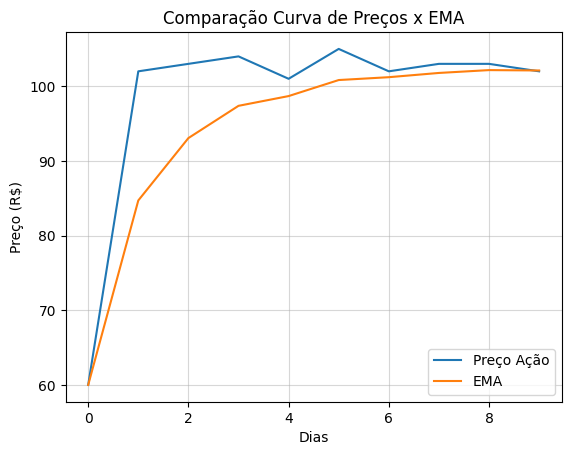

In [ ]:
# Geração do gráfico comparativo
plt.plot(carteira, label = 'Preço Ação')
plt.plot(st, label = 'EMA')
plt.xlabel("Dias")
plt.ylabel("Preço (R$)")
plt.title("Comparação Curva de Preços x EMA")
plt.legend()
plt.grid(alpha=0.5)
plt.show()

## **2. Exemplo real usando dados do YahooFinance!**

---

In [ ]:
# Baixa os dados do YahooFinance
ativo = yf.download('VALE3.SA', start='2025-01-01', end='2026-01-01')['Close']


[*********************100%***********************]  1 of 1 completed


In [ ]:
ativo # imprime cabeçalho e rodapé

Ticker,VALE3.SA
Date,
2025-01-02,46.624527
2025-01-03,45.756496
2025-01-06,45.172077
2025-01-07,44.733761
2025-01-08,44.304039
...,...
2025-12-22,70.929672
2025-12-23,70.910225
2025-12-26,71.124222


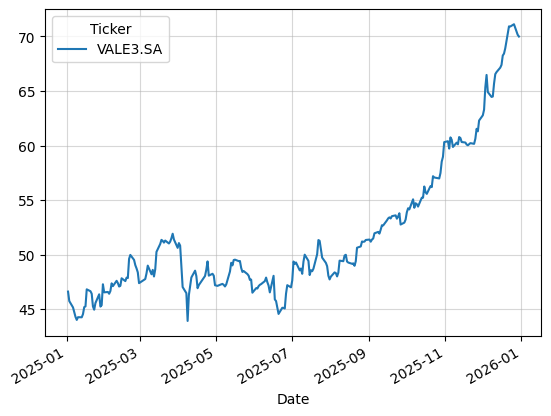

In [ ]:
ativo.plot() # gera o gráfico
plt.grid(alpha=0.5)

In [ ]:
# Suavização dos dados usando EWMA
st = ativo.ewm(alpha=0.3).mean()
st

Ticker,VALE3.SA
Date,
2025-01-02,46.624527
2025-01-03,46.113921
2025-01-06,45.683855
2025-01-07,45.308769
2025-01-08,44.946456
...,...
2025-12-22,68.809819
2025-12-23,69.439941
2025-12-26,69.945225


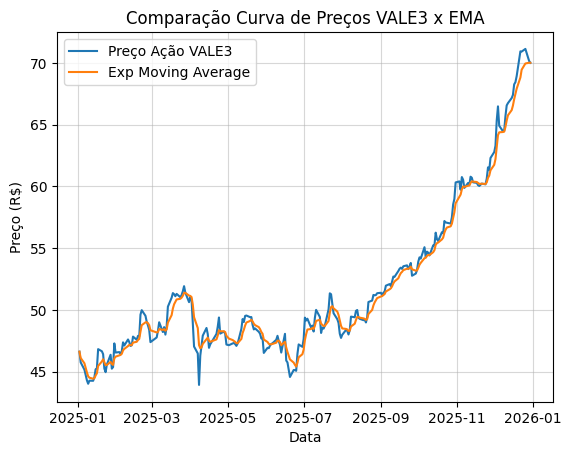

In [ ]:
# Geração do gráfico comparativo
plt.plot(ativo, label = 'Preço Ação VALE3')
plt.plot(st, label = 'Exp Moving Average')
plt.xlabel("Data")
plt.ylabel("Preço (R$)")
plt.title("Comparação Curva de Preços VALE3 x EMA")
plt.legend()
plt.grid(alpha=0.5)
plt.show()

## **3. Exemplo Extra**

---

In [ ]:
acao = yf.download('WEGE3.SA', start='2025-01-01', end='2026-01-01')['Close']

[*********************100%***********************]  1 of 1 completed


In [ ]:
acao

Ticker,WEGE3.SA
Date,
2025-01-02,49.654282
2025-01-03,49.409389
2025-01-06,49.418816
2025-01-07,50.407757
2025-01-08,50.115788
...,...
2025-12-22,47.347973
2025-12-23,47.963913
2025-12-26,48.430832


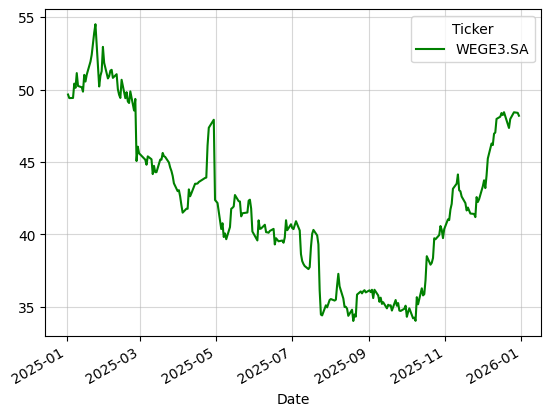

In [ ]:
acao.plot(color='green')
plt.grid(alpha=0.5)

In [ ]:
ut = acao.ewm(alpha=0.3).mean()
ut

Ticker,WEGE3.SA
Date,
2025-01-02,49.654282
2025-01-03,49.510227
2025-01-06,49.468487
2025-01-07,49.839300
2025-01-08,49.939003
...,...
2025-12-22,47.799879
2025-12-23,47.849089
2025-12-26,48.023612


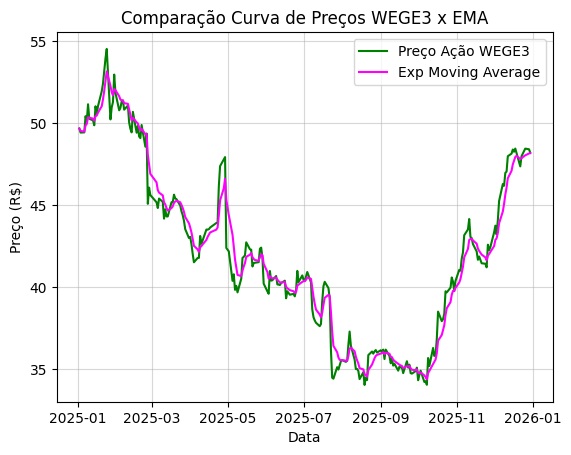

In [ ]:
# Geração do gráfico comparativo
plt.plot(acao, label = 'Preço Ação WEGE3', color='green')
plt.plot(ut, label = 'Exp Moving Average', color='magenta')
plt.xlabel("Data")
plt.ylabel("Preço (R$)")
plt.title("Comparação Curva de Preços WEGE3 x EMA")
plt.legend()
plt.grid(alpha=0.5)
plt.show()

:)